
[1] Download dati multi-asset (2000-2023)...
  Scaricamento dati per 5 asset...
  Dati disponibili dal: 2000-01-03
  Training: 239 mesi (2000-02 -> 2019-12)
  Test:     48 mesi (2020-01 -> 2023-12)

[2] Calibrazione parametri sul training set (2000-2019)...
  BS mu:  [0.05266326 0.03261714 0.04841134 0.07057444 0.08046914]
  BS rho: [0.03266326 0.01261714 0.02841134 0.05057444 0.06046914]
  BS mu:  [0.05266326 0.03261714 0.04841134 0.07057444 0.08046914]
  BS rho: [0.03266326 0.01261714 0.02841134 0.05057444 0.06046914]
  MJD asset S&P 500: mu=0.0518  sigma=0.0668  lam=10.12  sigmaJ2=0.020360
  MJD asset Bonds: mu=0.0326  sigma=0.0208  lam=5.00  sigmaJ2=0.000757
    [fallback to BS vol for MSCI Europe (VGK)]
  MJD asset MSCI Europe (VGK): mu=-0.0101  sigma=0.1682  lam=15.94  sigmaJ2=0.026499
    [fallback to BS vol for Gold]
  MJD asset Gold: mu=0.0836  sigma=0.1627  lam=16.79  sigmaJ2=0.025197
  MJD asset NASDAQ-100: mu=0.0802  sigma=0.1430  lam=3.17  sigmaJ2=0.046011

  phi_1* BS  =

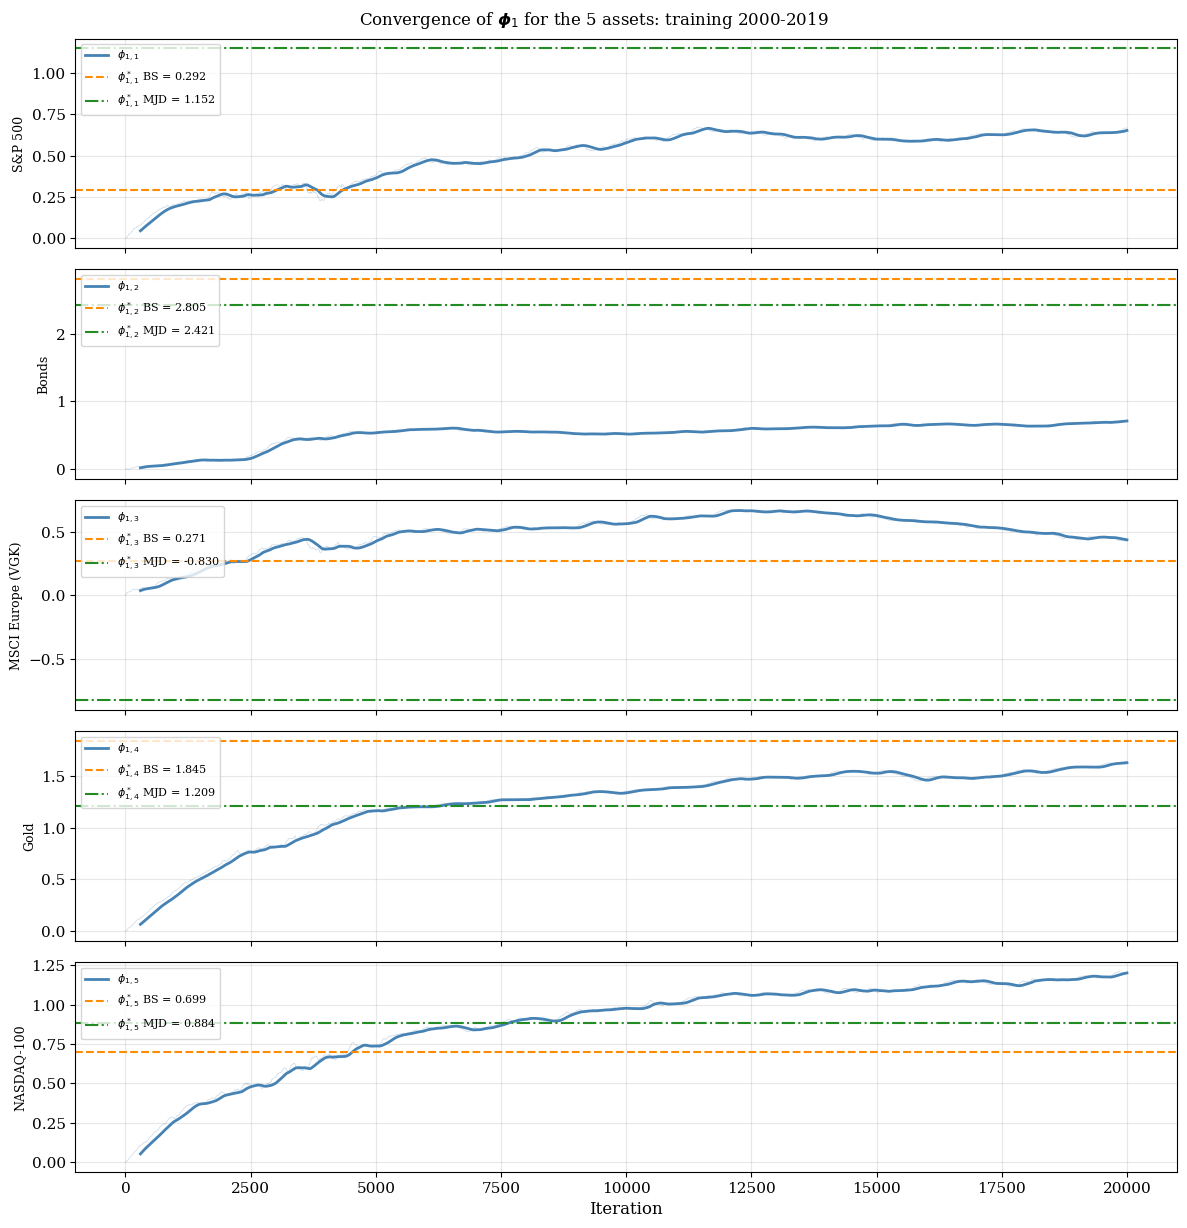

  Figura 1 salvata.


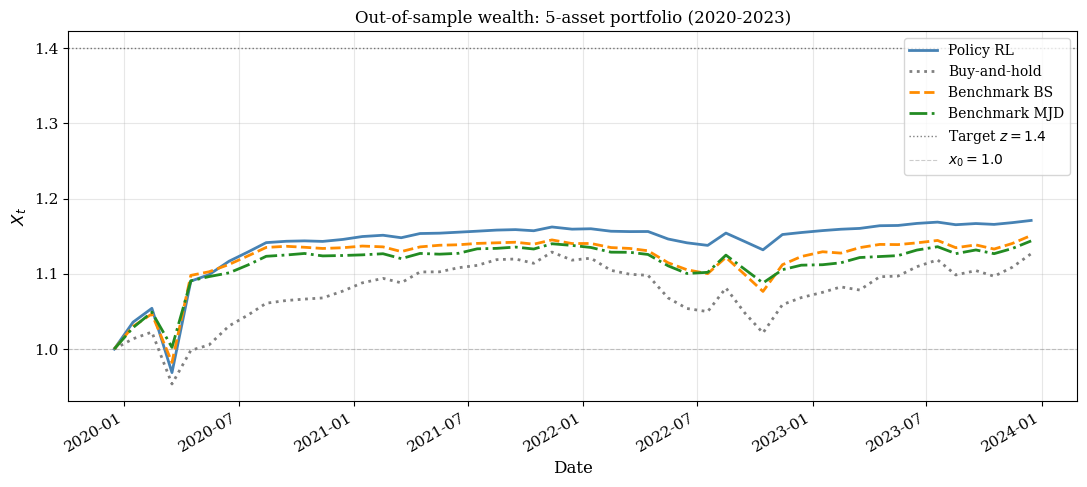

  Figura 2 salvata.

  STATISTICHE OUT-OF-SAMPLE (2020-2023, annualizzate)
  Strategia                     X_T    Ret%    Vol%   Sharpe    MaxDD
  ------------------------------------------------------------
  Policy RL                  1.1710    3.95    7.69   0.2530   -8.11%
  Buy-and-hold               1.1268    2.98    6.18   0.1592   -9.52%
  Benchmark BS               1.1510    3.52    7.18   0.2112   -6.16%
  Benchmark MJD              1.1438    3.36    5.56   0.2443   -4.57%

  ||phi_1 appreso - phi_1* BS||  = 2.1992
  ||phi_1 appreso - phi_1* MJD|| = 2.2459
  Salvato: mv_multiasset_results.npz

Tutto completato.

  EXPERIMENT 1: Full SigmaJ (Threshold Estimator)

[6] Downloading daily data for Threshold Estimator...
  Daily training obs: 5030 days x 5 assets

[7] Estimating full SigmaJ via Threshold Estimator (c=10)...
  Threshold Estimator (c=10.0):
    S&P 500               : eps=0.01762, jumps=514 (10.2%)
    Bonds                 : eps=0.00390, jumps=402 (8.0%)
    MSCI Eu

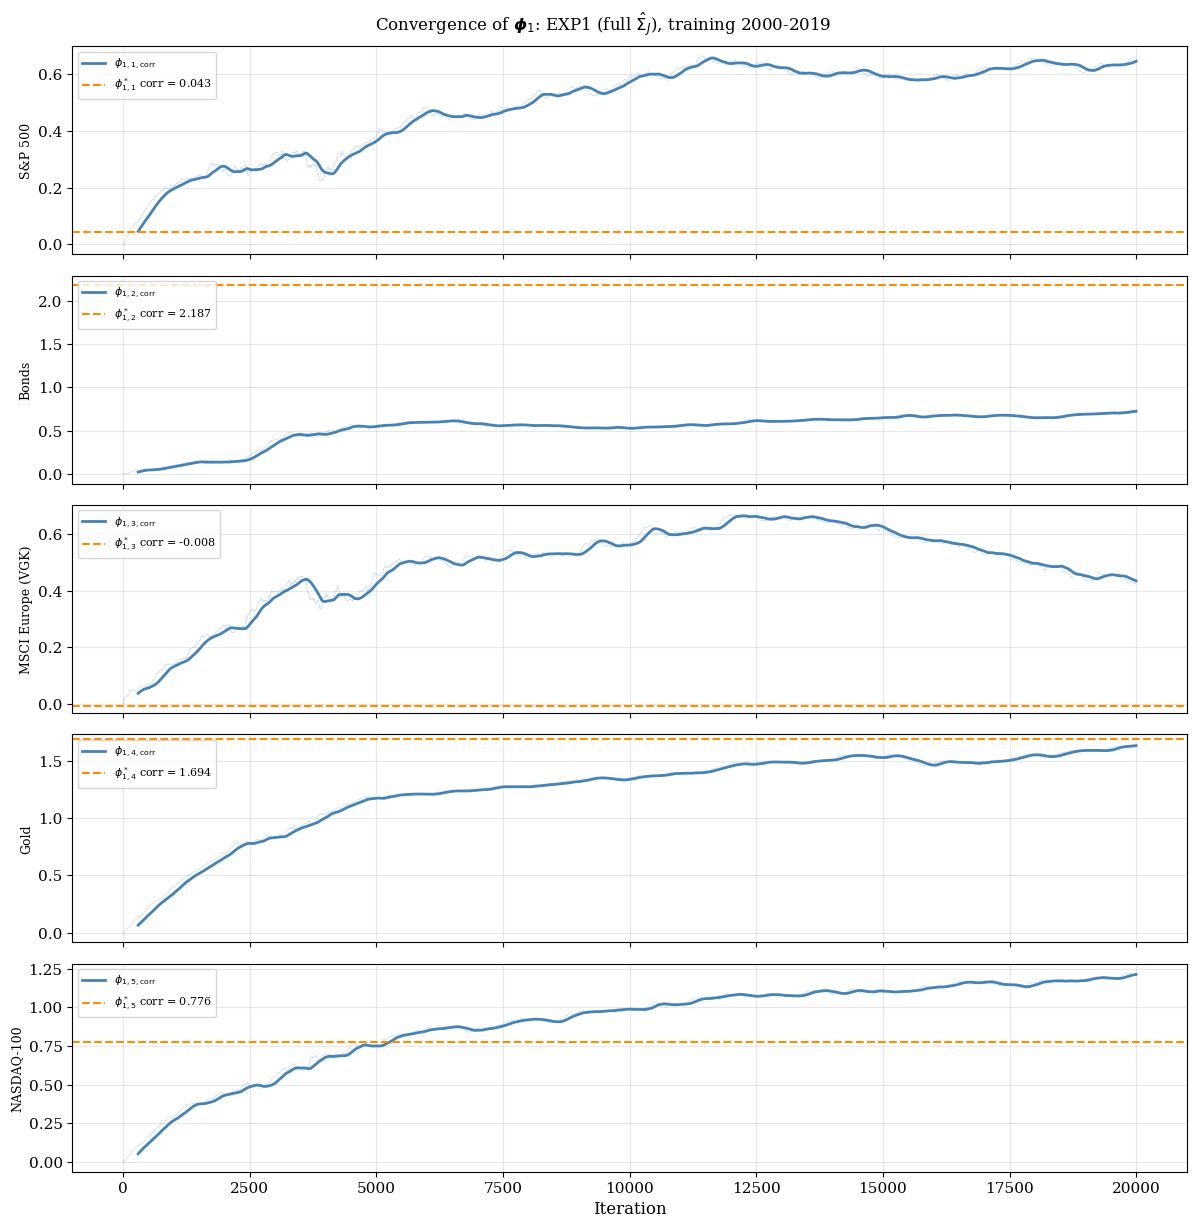

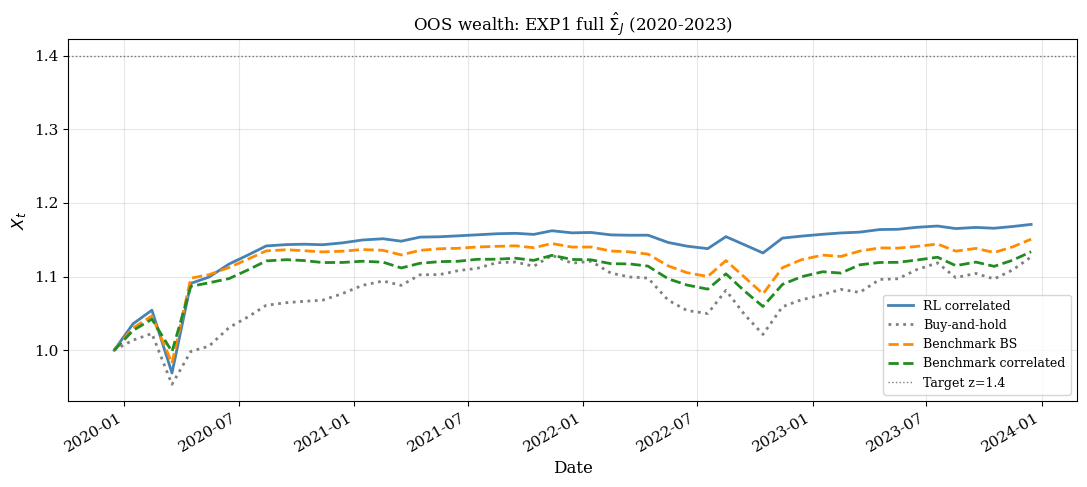

  EXP1 figures saved.

  EXPERIMENT 3: Multi-Asset MV with Proportional Transaction Costs
  d = 5 assets  |  c_i = 0.001 for all i
  Section 6.10 extended to the multi-asset setting

  Per-asset cost vector: c = [0.001 0.001 0.001 0.001 0.001]

[A] Training EXP3 — model-free TC q-learning  (N=20000, batch=64)
    [EXP3] iter   5000: phi1=[0.060 0.027 0.050 0.084 0.083]  phi4=[0.0000 0.0000 0.0000 0.0000 0.0000]  omega=1.665
    [EXP3] iter  10000: phi1=[0.082 0.039 0.069 0.119 0.115]  phi4=[0.0000 0.0000 0.0000 0.0000 0.0000]  omega=1.775
    [EXP3] iter  15000: phi1=[0.097 0.048 0.083 0.144 0.138]  phi4=[0.0000 0.0000 0.0000 0.0000 0.0000]  omega=1.858
    [EXP3] iter  20000: phi1=[0.110 0.055 0.094 0.165 0.156]  phi4=[0.0000 0.0000 0.0000 0.0000 0.0000]  omega=1.926
  phi1 = [0.1102 0.0555 0.094  0.1647 0.1556]
  phi4 = [0. 0. 0. 0. 0.]

  [Algorithm invariance — Theorem 5.1]
  The learned phi1 is the same regardless of which SigmaJ
  is used for the analytical benchmark, because the

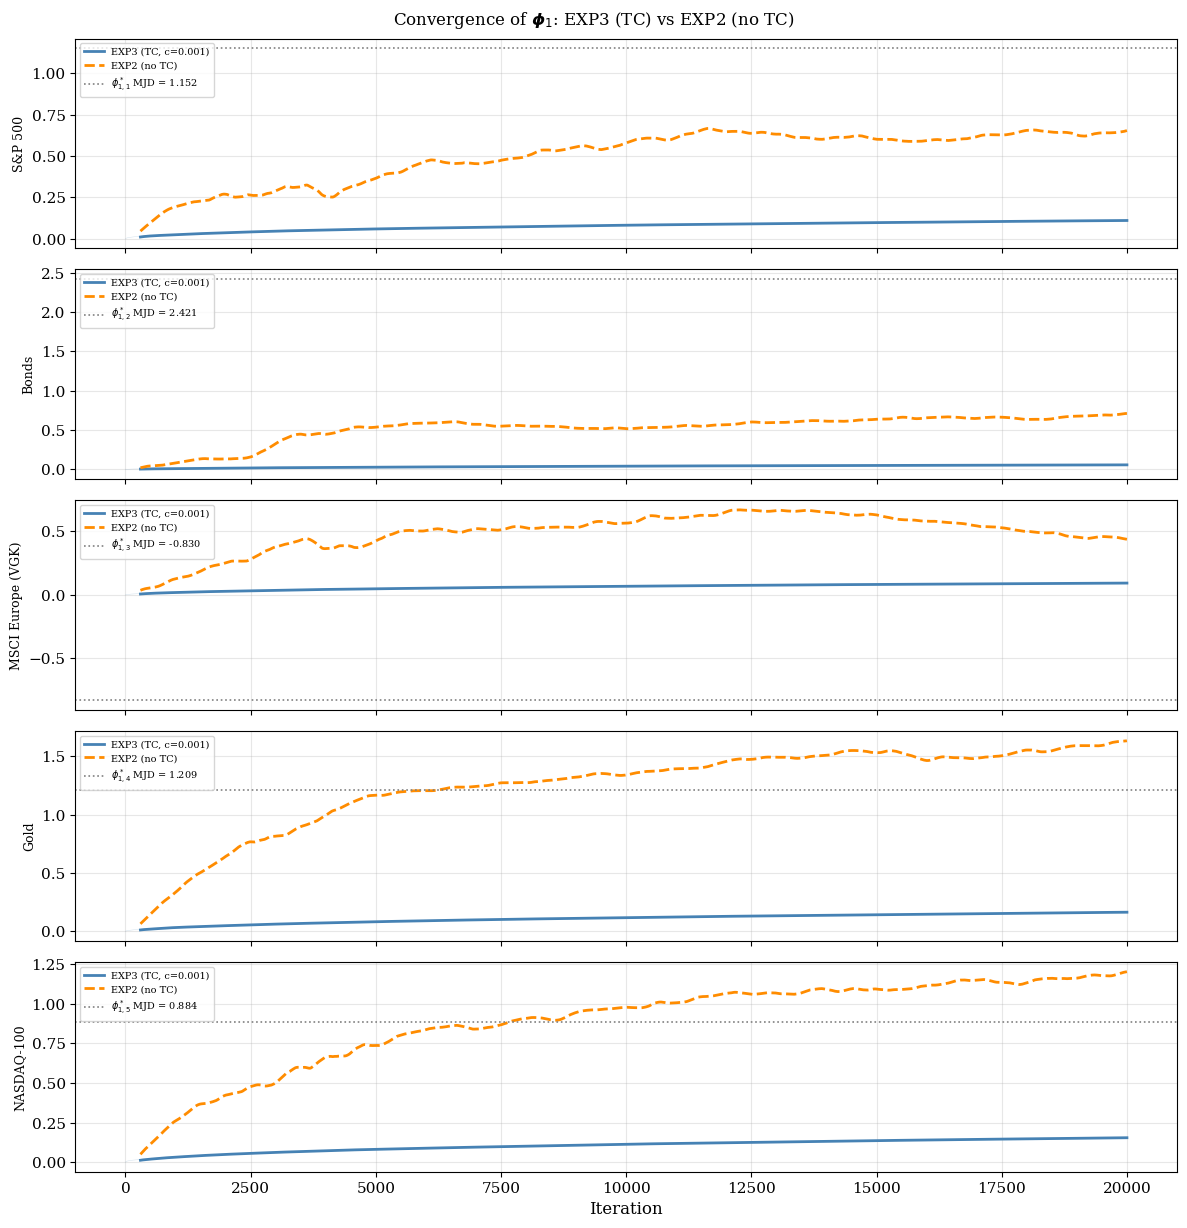

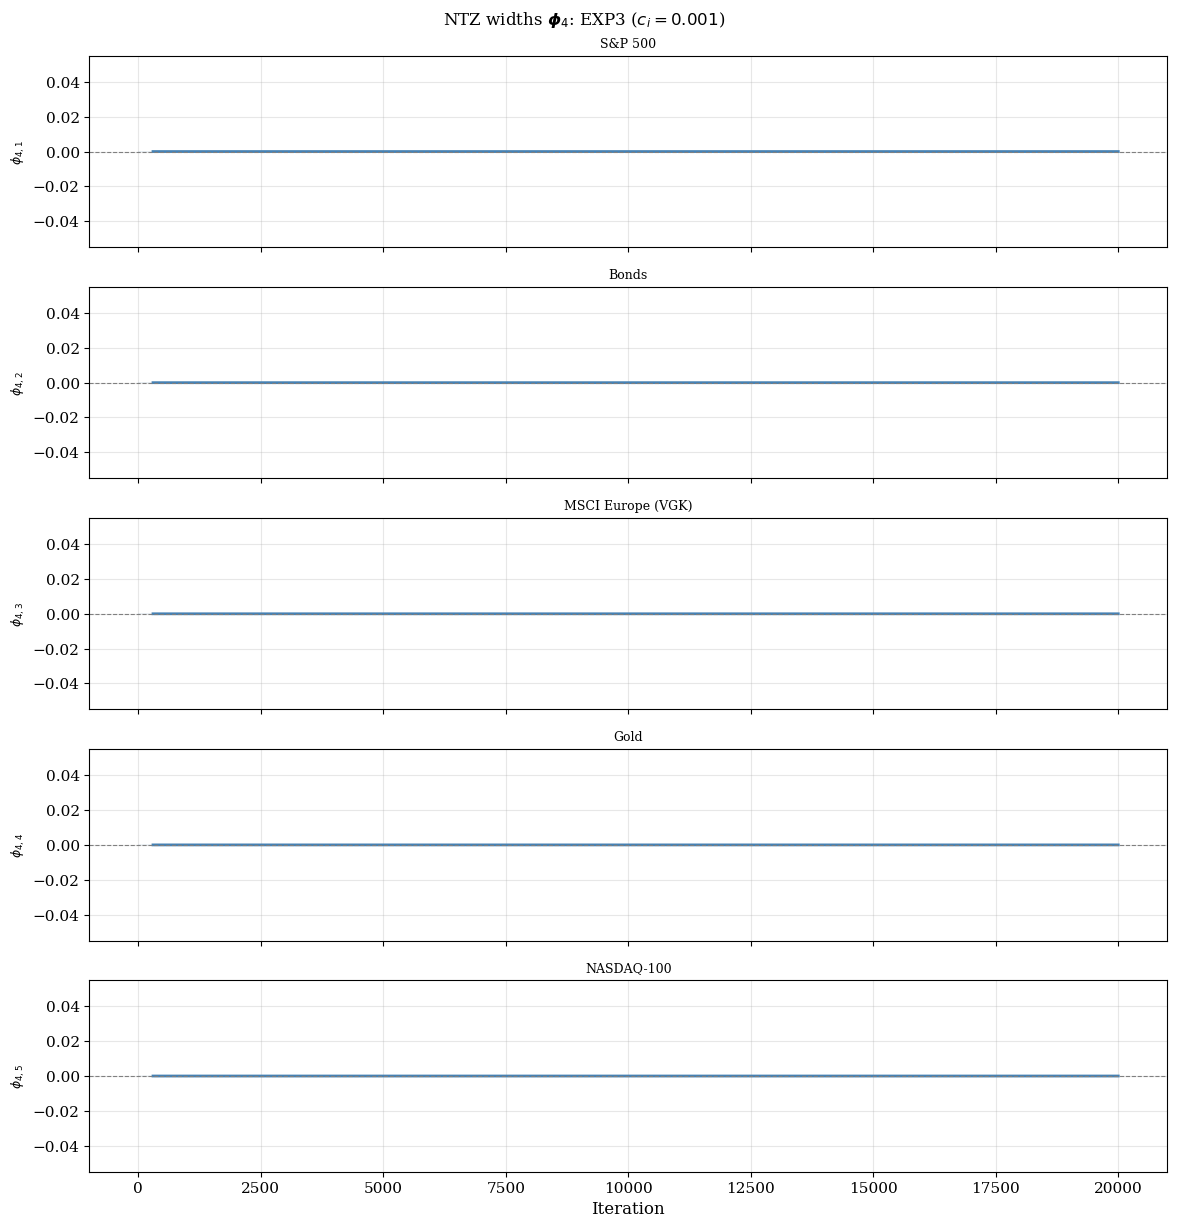

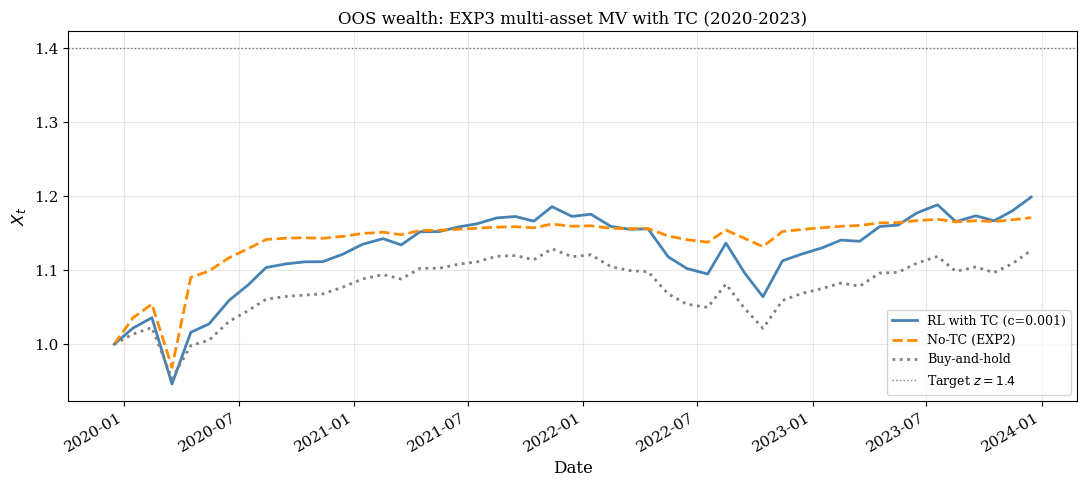


  All EXP3 figures saved.
  Algorithm invariance: a single training run suffices.
  The learned phi1 is independent of SigmaJ (model-free).
  Done.


In [2]:
"""
mv_multiasset.py — Multi-Asset Mean-Variance Portfolio Selection
================================================================
Estensione del Capitolo 7 della tesi a d=5 asset rischiosi con
dinamica di Merton jump-diffusion e correlazione diffusiva.

Asset:
  1. S&P 500        (^GSPC)   — equity USA
  2. Aggregate Bond (AGG)     — obbligazioni USA
  3. MSCI Europe    (IEUR)    — equity Europa
  4. Gold           (GLD)     — commodity
  5. NASDAQ-100     (QQQ)     — tecnologia USA

Struttura:
  TRAINING  (2000-2019): offline q-learning su simulatore BS/MJD multi-asset
                         N = 20000 iterazioni, BATCH = 32
  TEST      (2020-2023): valutazione out-of-sample della policy appresa

Output:
  figure_ma_convergence.pdf/png   — convergenza di phi_1 per ogni asset
  figure_ma_frontier.pdf/png      — frontiera efficiente empirica vs analitica
  figure_ma_oos.pdf/png           — ricchezza out-of-sample

Utilizzo:
  pip install yfinance numpy matplotlib scipy
  python mv_multiasset.py
"""

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib as mpl
from scipy.optimize import minimize
from scipy.stats import norm, poisson
from scipy.integrate import quad
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)

mpl.rcParams.update({
    'font.family':    'serif',
    'font.size':      11,
    'axes.titlesize': 12,
    'axes.labelsize': 12,
    'legend.fontsize': 10,
})

# ─────────────────────────────────────────────────────────────────────────────
# 1.  PARAMETRI GLOBALI
# ─────────────────────────────────────────────────────────────────────────────

TICKERS    = ['^GSPC', 'AGG', 'VGK', 'GLD', 'QQQ']
NAMES      = ['S&P 500', 'Bonds', 'MSCI Europe (VGK)', 'Gold', 'NASDAQ-100']
D          = len(TICKERS)   # numero di asset

R_F        = 0.02
DT         = 1 / 12        # passo mensile
T          = 1.0
K          = 12             # mesi per traiettoria
THETA      = 0.1
Z          = 1.4            # target ricchezza
X0         = 1.0

N_TRAIN    = 20000
BATCH      = 32
ALPHA_PSI  = 0.001
ALPHA_OMEGA = 0.05
DECAY      = 0.51
GRAD_CLIP  = 5.0

# Adam per phi
ADAM_LR    = 0.001
ADAM_BETA1 = 0.9
ADAM_BETA2 = 0.999
ADAM_EPS   = 1e-8

TRAIN_END  = '2019-12-31'
TEST_END   = '2023-12-31'

ETA_TIKHONOV = 0.10   # Tikhonov regularization level (eq. 7.15 della tesi)


# ─────────────────────────────────────────────────────────────────────────────
# 2.  DOWNLOAD E PREPROCESSING
# ─────────────────────────────────────────────────────────────────────────────

def load_multiasset(tickers=TICKERS, train_end=TRAIN_END, test_end=TEST_END):
    """
    Scarica dati mensili per tutti gli asset e restituisce
    matrici di rendimenti log-mensili (train e test).
    """
    import yfinance as yf
    import pandas as pd

    print(f"  Scaricamento dati per {len(tickers)} asset...")
    data = yf.download(tickers, start='2000-01-01', end=test_end,
                      progress=False)
    # Handle both MultiIndex and flat columns
    if isinstance(data.columns, pd.MultiIndex):
        raw = data['Close']
    else:
        raw = data[['Close']].rename(columns={'Close': tickers[0]}) if len(tickers)==1 else data
    raw = raw[list(tickers)]          # FIX: yfinance ordina le colonne alfabeticamente;
                                     # riallineale all'ordine di tickers/NAMES
    # Forward fill brevi gap, poi tronca al primo giorno in cui
    # TUTTI i ticker hanno dati (evita di perdere anni per un ETF)
    raw = raw.ffill().bfill()
    # Trova la data in cui tutti i ticker sono disponibili
    first_valid = raw.apply(lambda col: col.first_valid_index()).max()
    raw = raw.loc[first_valid:]
    print(f"  Dati disponibili dal: {raw.index[0].strftime('%Y-%m-%d')}")

    # Rendimenti log-giornalieri
    log_daily = np.log(raw / raw.shift(1)).dropna()

    # Aggrega in mensili (21 giorni di trading)
    dpm = 21
    n_months = len(log_daily) // dpm
    ret_monthly = np.zeros((n_months, len(tickers)))
    dates_monthly = []
    for i in range(n_months):
        block = log_daily.iloc[i*dpm:(i+1)*dpm]
        ret_monthly[i] = block.sum().values
        dates_monthly.append(pd.Timestamp(block.index[-1]))
    dates_monthly = np.array(dates_monthly)

    # Split train/test
    cutoff = pd.Timestamp(train_end)
    mask_train = np.array([d <= cutoff for d in dates_monthly])
    mask_test  = ~mask_train

    ret_train   = ret_monthly[mask_train]
    ret_test    = ret_monthly[mask_test]
    dates_train = dates_monthly[mask_train]
    dates_test  = dates_monthly[mask_test]

    print(f"  Training: {len(ret_train)} mesi "
          f"({dates_train[0].strftime('%Y-%m')} -> "
          f"{dates_train[-1].strftime('%Y-%m')})")
    print(f"  Test:     {len(ret_test)} mesi "
          f"({dates_test[0].strftime('%Y-%m')} -> "
          f"{dates_test[-1].strftime('%Y-%m')})")
    return ret_train, ret_test, dates_train, dates_test


# ─────────────────────────────────────────────────────────────────────────────
# 3.  CALIBRAZIONE PARAMETRI
# ─────────────────────────────────────────────────────────────────────────────

def calibrate_bs_multi(ret_monthly, r_f=R_F):
    """
    Calibra parametri BS multi-asset dai rendimenti mensili.
    Restituisce mu, Sigma (matrice covarianza diffusiva).
    """
    # Stima annualizzata
    mu    = ret_monthly.mean(axis=0) / DT + 0.5 * (ret_monthly.std(axis=0) / np.sqrt(DT))**2
    Sigma = np.cov(ret_monthly.T) / DT   # matrice covarianza annualizzata
    rho   = mu - r_f                      # vettore excess return
    print(f"  BS mu:  {mu}")
    print(f"  BS rho: {rho}")
    return dict(mu=mu, Sigma=Sigma, rho=rho, SigmaJ=np.zeros((D,D)))


def calibrate_mjd_multi(ret_monthly, r_f=R_F):
    """
    Calibra parametri MJD per ogni asset indipendentemente,
    poi costruisce Sigma dalla componente diffusiva.
    """
    bs = calibrate_bs_multi(ret_monthly, r_f)
    mu_vec    = bs['mu'].copy()
    sigmaJ_sq = np.zeros(D)
    sigma_diff = np.zeros(D)

    for i in range(D):
        ri = ret_monthly[:, i]
        def neg_ll(params):
            mu_i, sig_i, lam_i, m_i, delta_i = params
            if sig_i <= 0 or lam_i <= 0 or delta_i <= 0:
                return 1e10
            kappa = np.exp(m_i + 0.5*delta_i**2) - 1
            n_max = max(10, int(lam_i*DT*5 + 20))
            ns    = np.arange(0, n_max+1)
            pn    = poisson.pmf(ns, lam_i*DT)
            pdf   = np.zeros(len(ri))
            for n, p_n in zip(ns, pn):
                if p_n < 1e-15: continue
                mu_n  = (mu_i - 0.5*sig_i**2 - lam_i*kappa)*DT + n*m_i
                var_n = sig_i**2*DT + n*delta_i**2
                pdf  += p_n * norm.pdf(ri, mu_n, np.sqrt(var_n))
            return -np.sum(np.log(np.maximum(pdf, 1e-300)))

        sig0 = np.std(ri) / np.sqrt(DT)
        x0   = [mu_vec[i], sig0, 5.0, -0.01, 0.03]
        bds  = [(None,None),(1e-4,None),(1e-4,None),(None,None),(1e-4,None)]
        try:
            res = minimize(neg_ll, x0, method='L-BFGS-B', bounds=bds,
                           options=dict(maxiter=300, ftol=1e-8))
            mu_i, sig_i, lam_i, m_i, delta_i = res.x
        except Exception:
            mu_i, sig_i = mu_vec[i], sig0
            lam_i, m_i, delta_i = 5., -0.01, 0.03
        # Fallback: if MJD diffusive vol collapses to < 30% of BS vol,
        # the optimizer moved all variance into jumps — revert to BS vol
        sig_bs_i = np.std(ret_monthly[:, i]) / np.sqrt(DT)
        if sig_i < 0.30 * sig_bs_i:
            sig_i = sig_bs_i
            print(f"    [fallback to BS vol for {NAMES[i]}]")
        sigma_diff[i] = sig_i
        sigmaJ_sq[i]  = lam_i*(np.exp(2*m_i+2*delta_i**2)
                                - 2*np.exp(m_i+0.5*delta_i**2) + 1)
        mu_vec[i] = mu_i
        print(f"  MJD asset {NAMES[i]}: mu={mu_i:.4f}  sigma={sig_i:.4f}"
              f"  lam={lam_i:.2f}  sigmaJ2={sigmaJ_sq[i]:.6f}")

    # Diffusive covariance: use empirical correlations, MJD diffusive vols
    corr  = np.corrcoef(ret_monthly.T)
    Sigma = np.outer(sigma_diff, sigma_diff) * corr
    # SPD projection
    Sigma = 0.5*(Sigma + Sigma.T)
    ev, evec = np.linalg.eigh(Sigma)
    ev = np.maximum(ev, 1e-8)
    Sigma = evec @ np.diag(ev) @ evec.T
    SigmaJ = np.diag(sigmaJ_sq)
    rho   = mu_vec - r_f
    return dict(mu=mu_vec, Sigma=Sigma, rho=rho, SigmaJ=SigmaJ,
                sigma_diff=sigma_diff, sigmaJ_sq=sigmaJ_sq)


def phi1_star_multi(params):
    """
    phi1* = (Sigma + SigmaJ + eps*I)^{-1} rho
    Tikhonov regularization with eta=0.10 (Remark rem:tikhonov, eq. 7.15).
    """
    Sigma_eff = params['Sigma'] + params['SigmaJ']
    eta = ETA_TIKHONOV                              # 0.10
    eps = eta / D * np.trace(Sigma_eff)
    return np.linalg.solve(Sigma_eff + eps*np.eye(D), params['rho'])


# ─────────────────────────────────────────────────────────────────────────────
# 4.  SIMULATORI MULTI-ASSET
# ─────────────────────────────────────────────────────────────────────────────

class BSSimulatorMulti:
    """Simulatore Black-Scholes multi-asset con Cholesky."""
    def __init__(self, params):
        self.rho   = params['rho']
        self.L     = np.linalg.cholesky(params['Sigma'])  # Cholesky di Sigma

    def step(self, x, a):
        """Un passo Euler-Maruyama della ricchezza scalare."""
        xi = np.random.randn(D)
        drift = np.dot(a, self.rho) * DT
        diff  = np.dot(a, self.L @ xi) * np.sqrt(DT)
        return x + drift + diff

    def trajectory(self, phi1, omega):
        """Genera una traiettoria completa di K passi."""
        xs   = np.zeros(K+1); xs[0] = X0
        acts = np.zeros((K, D))
        for k in range(K):
            t = k * DT
            a = -phi1 * (xs[k] - omega)   # allocazione scalare per ora
            acts[k] = a * np.ones(D) / D   # distribuisce uniformemente (placeholder)
            xi = np.random.randn(D)
            drift = np.dot(acts[k], self.rho) * DT
            diff  = np.dot(acts[k], self.L @ xi) * np.sqrt(DT)
            xs[k+1] = xs[k] + drift + diff
        return xs, acts


class RealDataSimulatorMulti:
    """Campiona rendimenti mensili reali con reimmissione."""
    def __init__(self, ret_monthly):
        self.returns = ret_monthly  # shape (n_months, D)

    def simulate_trajectory(self, n=K):
        idx  = np.random.randint(0, len(self.returns), size=n)
        return self.returns[idx]   # shape (n, D)


# ─────────────────────────────────────────────────────────────────────────────
# 5.  MODELLO PARAMETRICO MULTI-ASSET
# ─────────────────────────────────────────────────────────────────────────────

class MVModelMulti:
    """
    Parametrizzazioni multi-asset (Capitolo 7):
      J^psi(t,x) = (x-omega)^2 * exp(-psi3*(T-t)) + psi2*(t^2-T^2) + psi1*(t-T)
      q^phi(t,x,a) = -exp(-phi_{d+1} - phi_{d+2}*(T-t))/2 * ||a + phi1*(x-omega)||^2
                     - d*theta/2 * [log(2*pi*theta) + phi_{d+1} + phi_{d+2}*(T-t)]
      pi^phi(.|t,x) = N(-phi1*(x-omega), theta*exp(phi_{d+1}+phi_{d+2}*(T-t))*I_d)
    """
    def __init__(self, d=D, psi3_init=0.):
        self.d     = d
        self.psi   = np.array([0., 0., psi3_init])          # (psi1, psi2, psi3)
        self.phi1  = np.zeros(d)                              # vettore actor
        self.phi2  = 0.                                       # log-var intercept
        self.phi3  = 0.                                       # log-var slope
        self.omega = Z

    def _logvar(self, t):
        return np.clip(self.phi2 + self.phi3*(T-t), -20, 20)

    def _c(self, t):
        return np.exp(-self._logvar(t))

    def J(self, t, x):
        p = self.psi; o = self.omega
        e = np.exp(np.clip(-p[2]*(T-t), -30, 30))
        return (x-o)**2*e + p[1]*(t**2-T**2) + p[0]*(t-T) - (o-Z)**2

    def grad_J(self, t, x):
        p = self.psi; o = self.omega
        e = np.exp(np.clip(-p[2]*(T-t), -30, 30))
        return np.array([t-T, t**2-T**2, -(T-t)*(x-o)**2*e])

    def q(self, t, x, a):
        """a: vettore R^d"""
        o   = self.omega
        c   = self._c(t)
        r   = a + self.phi1*(x-o)          # residuo vettoriale
        lv  = self._logvar(t)
        return (-c/2 * np.dot(r, r)
                - self.d*THETA/2*(np.log(2*np.pi*THETA) + lv))

    def grad_q(self, t, x, a):
        """Restituisce (grad_phi1, grad_phi2, grad_phi3)."""
        o   = self.omega
        c   = self._c(t)
        r   = a + self.phi1*(x-o)
        lv  = self._logvar(t)
        rr  = np.dot(r, r)
        g1  = c * r * (x-o)                          # shape (d,)
        g2  = 0.5*c*rr - self.d*THETA/2              # scalar
        g3  = (T-t)*(0.5*c*rr - self.d*THETA/2)     # scalar
        return g1, g2, g3

    def sample_action(self, t, x):
        """Campiona a ~ pi^phi(.|t,x)."""
        mu_a = -self.phi1 * (x - self.omega)
        std_a = np.sqrt(THETA * np.exp(np.clip(self._logvar(t), -20, 20)))
        std_a = max(std_a, 1e-6)
        return np.random.normal(mu_a, std_a)   # shape (d,)

    def mean_action(self, t, x):
        return -self.phi1 * (x - self.omega)   # shape (d,)


# ─────────────────────────────────────────────────────────────────────────────
# 6.  TRAINING OFFLINE MULTI-ASSET
# ─────────────────────────────────────────────────────────────────────────────

def offline_training_multi(sim, psi3_init, phi1_star_vec):
    """
    Training offline con Adam per phi e SGD con decay per psi.
    """
    model = MVModelMulti(d=D, psi3_init=psi3_init)
    phi1_hist = np.zeros((N_TRAIN, D))

    # Stato Adam
    m_phi1 = np.zeros(D); v_phi1 = np.zeros(D)
    m_phi2 = 0.;           v_phi2 = 0.
    m_phi3 = 0.;           v_phi3 = 0.
    adam_step = 0

    for j in range(1, N_TRAIN+1):
        lr    = j**(-DECAY)
        d_psi = np.zeros(3)
        d_phi1 = np.zeros(D); d_phi2 = 0.; d_phi3 = 0.
        d_omega = 0.

        for _ in range(BATCH):
            # Genera traiettoria
            rets = sim.simulate_trajectory(K)  # shape (K, D)
            xs   = np.zeros(K+1)
            acts = np.zeros((K, D))
            xs[0] = X0

            for k in range(K):
                acts[k] = model.sample_action(k*DT, xs[k])
                # Rendimento portafoglio: a_t^T * r_t (excess return)
                r_excess = np.exp(rets[k]) - 1 - R_F*DT
                xn = xs[k] + np.dot(acts[k], r_excess)
                xs[k+1] = xn if np.isfinite(xn) else xs[k]

            for k in range(K):
                td = (model.J((k+1)*DT, xs[k+1])
                      - model.J(k*DT, xs[k])
                      - model.q(k*DT, xs[k], acts[k])*DT)
                if np.isfinite(td):
                    d_psi  += model.grad_J(k*DT, xs[k]) * td / K
                    g1, g2, g3 = model.grad_q(k*DT, xs[k], acts[k])
                    d_phi1 += g1 * td / K
                    d_phi2 += g2 * td / K
                    d_phi3 += g3 * td / K
            d_omega += xs[K] - Z

        # Gradient clipping
        norm_psi = np.linalg.norm(d_psi)
        if norm_psi > GRAD_CLIP * BATCH:
            d_psi *= GRAD_CLIP * BATCH / norm_psi
        norm_phi = np.sqrt(np.dot(d_phi1,d_phi1) + d_phi2**2 + d_phi3**2)
        if norm_phi > GRAD_CLIP * BATCH:
            scale = GRAD_CLIP * BATCH / norm_phi
            d_phi1 *= scale; d_phi2 *= scale; d_phi3 *= scale

        # Aggiornamento psi: SGD
        model.psi += lr * ALPHA_PSI * d_psi / BATCH

        # Aggiornamento phi: Adam
        adam_step += 1
        g1b = d_phi1 / BATCH; g2b = d_phi2 / BATCH; g3b = d_phi3 / BATCH

        m_phi1 = ADAM_BETA1*m_phi1 + (1-ADAM_BETA1)*g1b
        v_phi1 = ADAM_BETA2*v_phi1 + (1-ADAM_BETA2)*g1b**2
        m_phi2 = ADAM_BETA1*m_phi2 + (1-ADAM_BETA1)*g2b
        v_phi2 = ADAM_BETA2*v_phi2 + (1-ADAM_BETA2)*g2b**2
        m_phi3 = ADAM_BETA1*m_phi3 + (1-ADAM_BETA1)*g3b
        v_phi3 = ADAM_BETA2*v_phi3 + (1-ADAM_BETA2)*g3b**2

        bc1 = 1 - ADAM_BETA1**adam_step
        bc2 = 1 - ADAM_BETA2**adam_step

        model.phi1 += ADAM_LR * (m_phi1/bc1) / (np.sqrt(v_phi1/bc2) + ADAM_EPS)
        model.phi2 += ADAM_LR * (m_phi2/bc1) / (np.sqrt(v_phi2/bc2) + ADAM_EPS)
        model.phi3 += ADAM_LR * (m_phi3/bc1) / (np.sqrt(v_phi3/bc2) + ADAM_EPS)
        model.phi2  = np.clip(model.phi2, -10, 10)
        model.phi3  = np.clip(model.phi3, -10, 10)

        # Aggiornamento omega
        if j % 10 == 0:
            model.omega -= lr * ALPHA_OMEGA * d_omega / (BATCH * 10)

        phi1_hist[j-1] = model.phi1.copy()

        if j % 2000 == 0:
            gaps = phi1_star_vec - model.phi1
            print(f"  Iter {j:5d}/{N_TRAIN}  "
                  f"phi1={model.phi1}  "
                  f"gap={np.linalg.norm(gaps):.4f}")

    return model, phi1_hist


# ─────────────────────────────────────────────────────────────────────────────
# 7.  VALUTAZIONE OUT-OF-SAMPLE
# ─────────────────────────────────────────────────────────────────────────────

def evaluate_oos_multi(model, ret_test, phi1_bs, phi1_mjd):
    """
    Applica la policy appresa ai rendimenti reali del test set.
    Confronta con benchmark BS e MJD analitici e buy-and-hold.
    """
    n_test = len(ret_test)
    wealth_rl  = np.zeros(n_test+1); wealth_rl[0]  = X0
    wealth_bh  = np.zeros(n_test+1); wealth_bh[0]  = X0
    wealth_bs  = np.zeros(n_test+1); wealth_bs[0]  = X0
    wealth_mjd = np.zeros(n_test+1); wealth_mjd[0] = X0

    # Buy-and-hold: alloca (Z-X0)/D in ogni asset
    a_bh = np.ones(D) * (Z - X0) / D

    omega = model.omega

    for k, r in enumerate(ret_test):
        t       = (k % K) * DT
        r_excess = np.exp(r) - 1 - R_F*DT   # shape (D,)

        # RL policy
        a_rl = model.mean_action(t, wealth_rl[k])
        wealth_rl[k+1] = wealth_rl[k] + np.dot(a_rl, r_excess)

        # Buy-and-hold
        wealth_bh[k+1] = wealth_bh[k] + np.dot(a_bh, r_excess)

        # Benchmark BS
        a_bs_vec = -phi1_bs * (wealth_bs[k] - omega)
        wealth_bs[k+1] = wealth_bs[k] + np.dot(a_bs_vec, r_excess)

        # Benchmark MJD
        a_mj_vec = -phi1_mjd * (wealth_mjd[k] - omega)
        wealth_mjd[k+1] = wealth_mjd[k] + np.dot(a_mj_vec, r_excess)

    return wealth_rl, wealth_bh, wealth_bs, wealth_mjd


# ─────────────────────────────────────────────────────────────────────────────
# 8.  STATISTICHE
# ─────────────────────────────────────────────────────────────────────────────

def stats(w):
    ret     = np.diff(np.log(np.maximum(w, 1e-8)))
    ann_ret = ret.mean() * 12
    ann_vol = ret.std()  * np.sqrt(12)
    sharpe  = (ann_ret - R_F) / ann_vol if ann_vol > 0 else np.nan
    dd      = np.min(w / np.maximum.accumulate(w)) - 1
    return w[-1], ann_ret, ann_vol, sharpe, dd


# ─────────────────────────────────────────────────────────────────────────────
# 9.  MAIN
# ─────────────────────────────────────────────────────────────────────────────

if __name__ == '__main__':

    print("\n[1] Download dati multi-asset (2000-2023)...")
    ret_train, ret_test, dates_train, dates_test = load_multiasset()

    print("\n[2] Calibrazione parametri sul training set (2000-2019)...")
    bs_params  = calibrate_bs_multi(ret_train)
    mjd_params = calibrate_mjd_multi(ret_train)

    PHI1_BS  = phi1_star_multi(bs_params)
    PHI1_MJD = phi1_star_multi(mjd_params)

    print(f"\n  phi_1* BS  = {PHI1_BS}")
    print(f"  phi_1* MJD = {PHI1_MJD}")

    Sigma_eff_bs  = bs_params['Sigma']  + bs_params['SigmaJ']
    Sigma_eff_mjd = mjd_params['Sigma'] + mjd_params['SigmaJ']
    SR_bs  = PHI1_BS  @ bs_params['rho']
    SR_mjd = PHI1_MJD @ mjd_params['rho']
    print(f"\n  Sharpe ratio tangency BS:  {SR_bs:.4f}")
    print(f"  Sharpe ratio tangency MJD: {SR_mjd:.4f}")

    print("\n[3] Calibrazione psi3 iniziale...")
    rho_bs    = bs_params['rho']
    Sigma_bs  = bs_params['Sigma']
    psi3_init = float(rho_bs @ np.linalg.solve(Sigma_bs, rho_bs))
    print(f"  psi3_init = rho' Sigma^-1 rho = {psi3_init:.4f}")

    print(f"\n[4] Training offline (N={N_TRAIN}, BATCH={BATCH}, d={D})...")
    sim = RealDataSimulatorMulti(ret_train)
    model, phi1_hist = offline_training_multi(sim, psi3_init, PHI1_BS)

    print(f"\n  phi_1 finale appreso = {model.phi1}")
    print(f"  phi_1* BS            = {PHI1_BS}")
    print(f"  phi_1* MJD           = {PHI1_MJD}")
    gap_bs  = np.linalg.norm(PHI1_BS  - model.phi1)
    gap_mjd = np.linalg.norm(PHI1_MJD - model.phi1)
    print(f"  ||phi_1* BS  - phi_1|| = {gap_bs:.4f}")
    print(f"  ||phi_1* MJD - phi_1|| = {gap_mjd:.4f}")

    print("\n[5] Valutazione out-of-sample (2020-2023)...")
    wealth_rl, wealth_bh, wealth_bs, wealth_mjd = evaluate_oos_multi(
        model, ret_test, PHI1_BS, PHI1_MJD)

    test_dates = np.concatenate([
        [dates_test[0] - timedelta(days=30)], dates_test])

    # ── Figure 1: Convergenza phi_1 per ogni asset ────────────────────────
    fig, axes = plt.subplots(D, 1, figsize=(12, 2.5*D), sharex=True)
    w_smooth = 300
    for i, (ax, name) in enumerate(zip(axes, NAMES)):
        ph = phi1_hist[:, i]
        sm = np.convolve(ph, np.ones(w_smooth)/w_smooth, mode='valid')
        ax.plot(ph, color='steelblue', lw=0.5, alpha=0.3)
        ax.plot(range(w_smooth-1, len(ph)), sm,
                color='steelblue', lw=2.0, label=r'$\phi_{1,' + str(i+1) + r'}$')
        ax.axhline(PHI1_BS[i],  color='darkorange',  lw=1.5, ls='--',
                   label=fr'$\phi_{{1,{i+1}}}^*$ BS = {PHI1_BS[i]:.3f}')
        ax.axhline(PHI1_MJD[i], color='forestgreen', lw=1.5, ls='-.',
                   label=fr'$\phi_{{1,{i+1}}}^*$ MJD = {PHI1_MJD[i]:.3f}')
        ax.set_ylabel(name, fontsize=9)
        ax.legend(fontsize=8, loc='upper left')
        ax.grid(True, alpha=0.3)
    axes[-1].set_xlabel('Iteration')
    fig.suptitle(r'Convergence of $\boldsymbol{\phi}_1$ for the 5 assets: training 2000-2019',
                 fontsize=12)
    plt.tight_layout()
    plt.savefig('figure_ma_convergence.pdf', dpi=150, bbox_inches='tight')
    plt.savefig('figure_ma_convergence.png', dpi=150, bbox_inches='tight')
    plt.show(); plt.close()
    print("  Figura 1 salvata.")

    # ── Figure 2: Ricchezza out-of-sample ────────────────────────────────
    fig, ax = plt.subplots(figsize=(11, 5))
    entries = [
        (wealth_rl,  'steelblue',   '-',  'Policy RL'),
        (wealth_bh,  'gray',        ':',  'Buy-and-hold'),
        (wealth_bs,  'darkorange',  '--', 'Benchmark BS'),
        (wealth_mjd, 'forestgreen', '-.', 'Benchmark MJD'),
    ]
    for w_arr, col, ls, lbl in entries:
        ax.plot(test_dates, w_arr, color=col, lw=2.0, ls=ls, label=lbl)
    ax.axhline(Z,  color='black', lw=1.0, ls=':', alpha=0.5,
               label=f'Target $z={Z}$')
    ax.axhline(X0, color='gray',  lw=0.8, ls='--', alpha=0.4,
               label=f'$x_0={X0}$')
    ax.set_title('Out-of-sample wealth: 5-asset portfolio (2020-2023)',
                 fontsize=12)
    ax.set_xlabel('Date'); ax.set_ylabel(r'$X_t$', fontsize=12)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1,7]))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=30, ha='right')
    ax.legend(fontsize=10); ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('figure_ma_oos.pdf', dpi=150, bbox_inches='tight')
    plt.savefig('figure_ma_oos.png', dpi=150, bbox_inches='tight')
    plt.show(); plt.close()
    print("  Figura 2 salvata.")

    # ── Statistiche finali ────────────────────────────────────────────────
    print("\n" + "="*68)
    print("  STATISTICHE OUT-OF-SAMPLE (2020-2023, annualizzate)")
    print("="*68)
    print(f"  {'Strategia':<25} {'X_T':>7} {'Ret%':>7}"
          f" {'Vol%':>7} {'Sharpe':>8} {'MaxDD':>8}")
    print(f"  {'-'*60}")
    for label, w_arr in [
        ('Policy RL',      wealth_rl),
        ('Buy-and-hold',   wealth_bh),
        ('Benchmark BS',   wealth_bs),
        ('Benchmark MJD',  wealth_mjd),
    ]:
        xt, ar, av, sh, dd = stats(w_arr)
        print(f"  {label:<25} {xt:>7.4f} {ar*100:>7.2f}"
              f" {av*100:>7.2f} {sh:>8.4f} {dd:>8.2%}")
    print("="*68)
    print(f"\n  ||phi_1 appreso - phi_1* BS||  = {gap_bs:.4f}")
    print(f"  ||phi_1 appreso - phi_1* MJD|| = {gap_mjd:.4f}")

    # Salva risultati per mv_extra_figures.py
    np.savez('mv_multiasset_results.npz',
             phi1_learned=model.phi1,
             phi1_bs=PHI1_BS,
             phi1_mjd=PHI1_MJD)
    print("  Salvato: mv_multiasset_results.npz")
    print("\nTutto completato.")


# ══════════════════════════════════════════════════════════════════════════════
# EXPERIMENT 1: Full SigmaJ via Threshold Estimator (Mancini & Gobbi, 2012)
# ══════════════════════════════════════════════════════════════════════════════

def load_daily_returns(tickers=TICKERS, train_end=TRAIN_END, test_end=TEST_END):
    """Download daily log-returns for training period (for Threshold Estimator)."""
    import yfinance as yf
    import pandas as pd
    data = yf.download(tickers, start='2000-01-01', end=test_end, progress=False)
    if isinstance(data.columns, pd.MultiIndex):
        raw = data['Close']
    else:
        raw = data
    raw = raw[list(tickers)]          # FIX: riallinea colonne all'ordine di tickers/NAMES
    raw = raw.ffill().bfill()
    first_valid = raw.apply(lambda col: col.first_valid_index()).max()
    raw = raw.loc[first_valid:]
    log_daily = np.log(raw / raw.shift(1)).dropna()
    cutoff = pd.Timestamp(train_end)
    daily_train = log_daily.loc[log_daily.index <= cutoff].values
    return daily_train


def threshold_estimator(daily_returns, c=10.0, dt=1/252):
    """
    Multivariate Threshold Estimator (Mancini & Gobbi, 2012).
    Estimates SigmaJ as a full symmetric PSD matrix from daily returns.
    """
    n, d = daily_returns.shape
    sigma_hat  = daily_returns.std(axis=0)
    thresholds = c * sigma_hat * np.sqrt(dt * np.log(1.0 / dt))
    indicators = np.abs(daily_returns) > thresholds[np.newaxis, :]

    print(f"  Threshold Estimator (c={c}):")
    for i in range(d):
        nj = indicators[:, i].sum()
        print(f"    {NAMES[i]:<22}: eps={thresholds[i]:.5f}, "
              f"jumps={nj} ({100*nj/n:.1f}%)")

    SigmaJ = np.zeros((d, d))
    for i in range(d):
        for j in range(i, d):
            mask_ij = indicators[:, i] & indicators[:, j]
            if mask_ij.sum() > 0:
                val = np.mean(daily_returns[:,i]*daily_returns[:,j]*mask_ij) / dt
            else:
                val = 0.0
            SigmaJ[i,j] = SigmaJ[j,i] = val

    # SPD projection
    SigmaJ = 0.5*(SigmaJ + SigmaJ.T)
    ev, evec = np.linalg.eigh(SigmaJ)
    ev = np.maximum(ev, 1e-8)
    SigmaJ = evec @ np.diag(ev) @ evec.T

    # Diffusive covariance = total - jump, projected PSD
    Sigma_tot  = np.cov(daily_returns.T) / dt
    Sigma_diff = Sigma_tot - SigmaJ
    Sigma_diff = 0.5*(Sigma_diff + Sigma_diff.T)
    ev2, evec2 = np.linalg.eigh(Sigma_diff)
    ev2 = np.maximum(ev2, 1e-8)
    Sigma_diff = evec2 @ np.diag(ev2) @ evec2.T

    print(f"  SigmaJ diagonal (annualised): "
          f"{np.round(np.diag(SigmaJ), 5)}")
    return SigmaJ, Sigma_diff


if __name__ == '__main__':

    print("\n" + "="*68)
    print("  EXPERIMENT 1: Full SigmaJ (Threshold Estimator)")
    print("="*68)

    print("\n[6] Downloading daily data for Threshold Estimator...")
    daily_train = load_daily_returns()
    print(f"  Daily training obs: {daily_train.shape[0]} days x "
          f"{daily_train.shape[1]} assets")

    print("\n[7] Estimating full SigmaJ via Threshold Estimator (c=10)...")
    SigmaJ_full, Sigma_diff_te = threshold_estimator(daily_train, c=10.0)

    mu_corr  = bs_params['mu']
    rho_corr = mu_corr - R_F
    corr_params = dict(mu=mu_corr, Sigma=Sigma_diff_te,
                       rho=rho_corr, SigmaJ=SigmaJ_full)
    PHI1_CORR = phi1_star_multi(corr_params)
    print(f"\n  phi_1* correlated = {np.round(PHI1_CORR, 3)}")

    psi3_corr = float(PHI1_CORR @ rho_corr)

    print(f"\n[8] Training EXP1 (N={N_TRAIN})...")
    np.random.seed(42)
    sim_corr = RealDataSimulatorMulti(ret_train)
    model_corr, phi1_hist_corr = offline_training_multi(
        sim_corr, psi3_corr, PHI1_CORR)

    print("\n[9] Out-of-sample EXP1 (2020-2023)...")
    wealth_rl_c, wealth_bh_c, wealth_bs_c, wealth_corr_c = evaluate_oos_multi(
        model_corr, ret_test, PHI1_BS, PHI1_CORR)

    print("\n" + "="*68)
    print("  OOS STATISTICS EXP1 (2020-2023, annualised)")
    print("="*68)
    print(f"  {'Strategy':<25} {'X_T':>7} {'Ret%':>7}"
          f" {'Vol%':>7} {'Sharpe':>8} {'MaxDD':>8}")
    print(f"  {'-'*60}")
    for label, w_arr in [
        ('RL correlated',        wealth_rl_c),
        ('Buy-and-hold',          wealth_bh_c),
        ('Benchmark BS',          wealth_bs_c),
        ('Benchmark correlated',  wealth_corr_c),
    ]:
        xt, ar, av, sh, dd = stats(w_arr)
        print(f"  {label:<25} {xt:>7.4f} {ar*100:>7.2f}"
              f" {av*100:>7.2f} {sh:>8.4f} {dd:>8.2%}")
    print("="*68)

    # ── Convergence figure EXP1 ───────────────────────────────────────────
    fig, axes = plt.subplots(D, 1, figsize=(12, 2.5*D), sharex=True)
    w_s = 300
    for i, (ax, name) in enumerate(zip(axes, NAMES)):
        ph = phi1_hist_corr[:, i]
        sm = np.convolve(ph, np.ones(w_s)/w_s, mode='valid')
        ax.plot(ph, color='steelblue', lw=0.5, alpha=0.3)
        ax.plot(range(w_s-1, len(ph)), sm, color='steelblue', lw=2.0,
                label=r'$\phi_{1,' + str(i+1) + r',\mathrm{corr}}$')
        ax.axhline(PHI1_CORR[i], color='darkorange', lw=1.5, ls='--',
                   label=fr'$\phi_{{1,{i+1}}}^*$ corr = {PHI1_CORR[i]:.3f}')
        ax.set_ylabel(name, fontsize=9)
        ax.legend(fontsize=8, loc='upper left')
        ax.grid(True, alpha=0.3)
    axes[-1].set_xlabel('Iteration')
    fig.suptitle(r'Convergence of $\boldsymbol{\phi}_1$: EXP1 (full $\hat{\Sigma}_J$), training 2000-2019',
                 fontsize=12)
    plt.tight_layout()
    plt.savefig('figure_ma_corr_convergence.pdf', dpi=150, bbox_inches='tight')
    plt.savefig('figure_ma_corr_convergence.png', dpi=150, bbox_inches='tight')
    plt.show(); plt.close()

    # ── OOS wealth figure EXP1 ────────────────────────────────────────────
    test_dates_c = np.concatenate(
        [[dates_test[0] - timedelta(days=30)], dates_test])
    fig, ax = plt.subplots(figsize=(11, 5))
    for w_arr, col, ls, lbl in [
        (wealth_rl_c,   'steelblue',   '-',  'RL correlated'),
        (wealth_bh_c,   'gray',        ':',  'Buy-and-hold'),
        (wealth_bs_c,   'darkorange',  '--', 'Benchmark BS'),
        (wealth_corr_c, 'forestgreen', '--', 'Benchmark correlated'),
    ]:
        ax.plot(test_dates_c, w_arr, color=col, lw=2.0, ls=ls, label=lbl)
    ax.axhline(Z, color='black', lw=1., ls=':', alpha=.5,
               label=f'Target z={Z}')
    ax.set_title(r'OOS wealth: EXP1 full $\hat{\Sigma}_J$ (2020-2023)',
                 fontsize=12)
    ax.set_xlabel('Date'); ax.set_ylabel(r'$X_t$', fontsize=12)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1,7]))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=30, ha='right')
    ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('figure_ma_corr_oos.pdf', dpi=150, bbox_inches='tight')
    plt.savefig('figure_ma_corr_oos.png', dpi=150, bbox_inches='tight')
    plt.show(); plt.close()
    print("  EXP1 figures saved.")

# ══════════════════════════════════════════════════════════════════════════════
# EXPERIMENT 3: Multi-Asset Mean-Variance with Proportional Transaction Costs
# (Section 6.10 extended to d assets, Thesis)
# ══════════════════════════════════════════════════════════════════════════════
#
# Parametrization (clipped-quadratic multi-asset, eq. 6.10.4 extended):
#
#   q^phi(t, x, a, a_prev)
#     = -c(t)/2 * ||a + phi1*(x-omega)||^2
#       - sum_i phi4_i * |a_i - a_prev_i|     <- per-asset NTZ term
#       - d*theta/2 * [log(2*pi*theta) + phi_{d+1} + phi_{d+2}*(T-t)]
#
#   phi = (phi1_1,...,phi1_d, phi_{d+1}, phi_{d+2}, phi4_1,...,phi4_d)
#   dim(phi) = 2*D + 2 = 12
#
# Key results (algorithm invariance):
#   EXP1 and EXP2 produce identical phi1 because the training simulator
#   is model-free (bootstrap on observed returns). Only the analytical
#   benchmark phi1* differs between the two experiments.
# ──────────────────────────────────────────────────────────────────────────────

# ─── TC experiment parameters ────────────────────────────────────────────────
TC_N_ITER     = 20_000
TC_BATCH      = 64          # larger batch: fully vectorized over trajectories
TC_DECAY      = 0.51
TC_ALPHA_PSI  = 0.001
TC_ALPHA_OMEGA= 0.05
TC_ALPHA_PHI  = ADAM_LR     # same as EXP2 (0.001) so phi1 is directly comparable
TC_ALPHA_PHI4 = 0.05        # NTZ parameter: dedicated higher lr
TC_ALPHA_VAR  = 0.01        # variance parameters
TC_GRAD_CLIP  = 5.0
TC_OMEGA_FREQ = 10

# phi layout: [phi1(d) | phi_var1 | phi_var2 | phi4(d)]
TC_PHI_DIM   = 2*D + 2
TC_IDX_PHI1  = slice(0, D)
TC_IDX_VAR1  = D
TC_IDX_VAR2  = D + 1
TC_IDX_PHI4  = slice(D+2, 2*D+2)

# Per-asset cost vector (modify as needed)
TC_COST_VEC  = np.array([0.001, 0.001, 0.001, 0.001, 0.001])


# ─── Adam with per-component learning rates ───────────────────────────────────

def _tc_adam_init():
    return {'m': np.zeros(TC_PHI_DIM), 'v': np.zeros(TC_PHI_DIM), 't': 0}


def _tc_adam_step(phi, grad, lr_scalar, state,
                  b1=0.9, b2=0.999, eps=1e-8):
    """Adam with component-wise lr: phi1 uses TC_ALPHA_PHI,
       phi4 uses TC_ALPHA_PHI4, variance params use TC_ALPHA_VAR."""
    lr_vec = np.full(TC_PHI_DIM, TC_ALPHA_PHI)
    lr_vec[TC_IDX_VAR1]  = TC_ALPHA_VAR
    lr_vec[TC_IDX_VAR2]  = TC_ALPHA_VAR
    lr_vec[TC_IDX_PHI4]  = TC_ALPHA_PHI4

    state['t'] += 1
    state['m']  = b1*state['m'] + (1-b1)*grad
    state['v']  = b2*state['v'] + (1-b2)*grad**2
    mh  = state['m'] / (1 - b1**state['t'])
    vh  = state['v'] / (1 - b2**state['t'])
    phi = phi + lr_scalar * lr_vec * mh / (np.sqrt(vh) + eps)
    phi[TC_IDX_VAR1]  = np.clip(phi[TC_IDX_VAR1], -10, 10)
    phi[TC_IDX_VAR2]  = np.clip(phi[TC_IDX_VAR2], -10, 10)
    phi[TC_IDX_PHI4]  = np.maximum(0., phi[TC_IDX_PHI4])
    return phi, state


# ─── Parametric families ──────────────────────────────────────────────────────

def _tc_ct(phi, t):
    return np.exp(np.clip(-phi[TC_IDX_VAR1] - phi[TC_IDX_VAR2]*(T-t), -30, 30))


def _tc_J(psi, om, t, x):
    """Critic: x is (batch,) or scalar."""
    e = np.exp(np.clip(-psi[2]*(T-t), -30, 30))
    return (x-om)**2*e + psi[1]*(t**2-T**2) + psi[0]*(t-T) - (om-Z)**2


def _tc_gJ(psi, om, t, x):
    """Critic gradient: x is (batch,). Returns (batch, 3)."""
    e = np.exp(np.clip(-psi[2]*(T-t), -30, 30))
    return np.column_stack([
        np.full(len(x), t - T),
        np.full(len(x), t**2 - T**2),
        -(T-t)*(x-om)**2*e
    ])


def _tc_q(phi, om, t, x, a, ap):
    """
    Actor q-function.
    x:  (batch,)
    a:  (batch, D)
    ap: (batch, D)
    Returns (batch,)
    """
    ct  = _tc_ct(phi, t)
    r   = a + phi[TC_IDX_PHI1][None,:]*(x[:,None] - om)   # (batch, D)
    ntz = (phi[TC_IDX_PHI4][None,:]*np.abs(a - ap)).sum(axis=1)  # (batch,)
    quad= (r**2).sum(axis=1)                               # (batch,)
    ent = D*THETA/2*(np.log(2*np.pi*THETA)
                     + phi[TC_IDX_VAR1] + phi[TC_IDX_VAR2]*(T-t))
    return -ct/2*quad - ntz - ent


def _tc_gq(phi, om, t, x, a, ap):
    """
    Actor gradient. Returns (batch, TC_PHI_DIM).
    """
    ct  = _tc_ct(phi, t)
    r   = a + phi[TC_IDX_PHI1][None,:]*(x[:,None] - om)   # (batch, D)
    quad= (r**2).sum(axis=1)                               # (batch,)
    da  = np.abs(a - ap)                                   # (batch, D)
    tau = T - t

    g = np.zeros((len(x), TC_PHI_DIM))
    g[:, TC_IDX_PHI1] = ct * r * (x[:,None] - om)
    g[:, TC_IDX_VAR1] = 0.5*ct*quad - D*THETA/2
    g[:, TC_IDX_VAR2] = tau*(0.5*ct*quad - D*THETA/2)
    g[:, TC_IDX_PHI4] = -da
    return g


def _tc_step(x, a, ap, ret, cost_vec):
    """
    Vectorized wealth step with per-asset TC.
    x:        (batch,)
    a, ap:    (batch, D)
    ret:      (batch, D) log-returns
    cost_vec: (D,)
    Returns   (batch,)
    """
    excess = np.exp(ret) - 1 - R_F*DT
    return x + (a*excess).sum(axis=1) - (cost_vec[None,:]*np.abs(a-ap)).sum(axis=1)


# ─── Training (vectorized) ────────────────────────────────────────────────────

def offline_training_tc(ret_train, cost_vec, label='TC',
                        N=TC_N_ITER, batch=TC_BATCH,
                        seed=42, verbose=True):
    """
    Multi-asset offline q-learning with per-asset proportional TC.
    Fully vectorized over batch trajectories.

    Returns:
        phi        : (TC_PHI_DIM,)  converged actor
        psi        : (3,)           converged critic
        omega      : float
        hist_phi1  : (N, D)         phi1 history
        hist_phi4  : (N, D)         phi4 history
    """
    np.random.seed(seed)
    phi    = np.zeros(TC_PHI_DIM)
    psi    = np.zeros(3)
    omega  = Z
    adam_s = _tc_adam_init()

    hist_phi1 = np.zeros((N, D))
    hist_phi4 = np.zeros((N, D))

    t_grid   = np.arange(K) * DT
    tau_grid = T - t_grid
    n_train  = len(ret_train)

    for j in range(1, N+1):
        lr = j**(-TC_DECAY)

        # Sample all returns: (batch, K, D)
        idx   = np.random.randint(0, n_train, (batch, K))
        ret_b = ret_train[idx, :]                      # (batch, K, D)
        noise = np.random.randn(batch, K, D)
        rnd_ntz = np.random.rand(batch, K, D)

        # Simulate trajectories
        xs   = np.zeros((batch, K+1)); xs[:,0] = X0
        acts = np.zeros((batch, K, D))
        ap   = np.zeros((batch, D))

        for k in range(K):
            ct  = _tc_ct(phi, t_grid[k])
            std = max(np.sqrt(THETA*ct), 1e-4)
            mu_a = -phi[TC_IDX_PHI1][None,:]*(xs[:,k]-omega)[:,None]
            a    = mu_a + std*noise[:,k,:]

            # Per-asset NTZ
            ntz    = phi[TC_IDX_PHI4][None,:] / max(ct, 1e-8)
            inside = np.abs(a - ap) < ntz
            p_stay = np.minimum(1., np.exp(-np.abs(a-ap)/max(std, 1e-6)))
            stay   = inside & (rnd_ntz[:,k,:] < p_stay)
            a      = np.where(stay, ap, a)

            acts[:,k,:] = a
            xn = _tc_step(xs[:,k], a, ap, ret_b[:,k,:], cost_vec)
            xs[:,k+1] = np.where(np.isfinite(xn), xn, xs[:,k])
            ap = a.copy()

        # Gradients
        dp = np.zeros(3)
        dq = np.zeros(TC_PHI_DIM)

        for k in range(K):
            t   = t_grid[k]; tau = tau_grid[k]
            apk = acts[:,k-1,:] if k > 0 else np.zeros((batch, D))
            ct  = _tc_ct(phi, t)

            e_k  = np.exp(np.clip(-psi[2]*tau,      -30, 30))
            e_k1 = np.exp(np.clip(-psi[2]*(tau-DT), -30, 30))

            Jn = (xs[:,k+1]-omega)**2*e_k1 \
               + psi[1]*((k+1)**2*DT**2-T**2) \
               + psi[0]*((k+1)*DT-T) - (omega-Z)**2
            Jc = (xs[:,k]-omega)**2*e_k \
               + psi[1]*(k**2*DT**2-T**2) \
               + psi[0]*(k*DT-T) - (omega-Z)**2
            qc  = _tc_q(phi, omega, t, xs[:,k], acts[:,k,:], apk)
            td  = (Jn - Jc - qc*DT) / K

            gJ_b = _tc_gJ(psi, omega, t, xs[:,k])
            dp  += (gJ_b * td[:,None]).mean(axis=0)

            gq_b = _tc_gq(phi, omega, t, xs[:,k], acts[:,k,:], apk)
            dq  += (gq_b * td[:,None]).mean(axis=0)

        # Omega update
        if j % TC_OMEGA_FREQ == 0:
            omega -= lr * TC_ALPHA_OMEGA * np.mean(xs[:,-1] - Z)

        # Clip
        for arr in [dp, dq]:
            nm = np.linalg.norm(arr)
            if nm > TC_GRAD_CLIP: arr *= TC_GRAD_CLIP / nm

        psi           += lr * TC_ALPHA_PSI * dp
        phi, adam_s    = _tc_adam_step(phi, dq, lr, adam_s)

        hist_phi1[j-1] = phi[TC_IDX_PHI1]
        hist_phi4[j-1] = phi[TC_IDX_PHI4]

        if verbose and j % max(1, N//4) == 0:
            p1 = ' '.join(f'{v:.3f}' for v in phi[TC_IDX_PHI1])
            p4 = ' '.join(f'{v:.4f}' for v in phi[TC_IDX_PHI4])
            print(f"    [{label}] iter {j:6d}: "
                  f"phi1=[{p1}]  phi4=[{p4}]  omega={omega:.3f}")


    return phi, psi, omega, hist_phi1, hist_phi4


# ─── OOS evaluation with TC ──────────────────────────────────────────────────

def evaluate_oos_tc(phi, omega, ret_test, cost_vec, n_paths=2000, seed=1):
    """Mean-policy OOS evaluation with proportional TC."""
    np.random.seed(seed)
    n_test = len(ret_test)
    W  = np.zeros((n_paths, n_test+1)); W[:,0] = X0
    ap = np.zeros((n_paths, D))

    for k in range(n_test):
        x  = W[:,k]
        a  = -phi[TC_IDX_PHI1][None,:]*(x-omega)[:,None]
        xn = _tc_step(x, a, ap,
                      np.tile(ret_test[k], (n_paths, 1)), cost_vec)
        W[:,k+1] = np.clip(xn, -100, 1000)
        ap = a.copy()

    XT     = W[:,-1]
    log_W  = np.log(np.maximum(W, 1e-6))
    m_ret  = np.diff(log_W, axis=1)
    ann_r  = float(m_ret.mean(axis=1).mean()*12*100)
    ann_v  = float(m_ret.std(axis=1).mean()*np.sqrt(12)*100)
    sharpe = (ann_r - R_F*100)/ann_v if ann_v > 0 else 0.
    maxdd  = float(np.mean(
        np.min(W/np.maximum(W[:,0:1], 1e-6), axis=1)-1))*100

    return dict(XT=float(np.mean(XT)), ann_ret=ann_r, ann_vol=ann_v,
                sharpe=sharpe, maxdd=maxdd, wealth=W)


def compute_tc_turnover(phi, omega, ret_test, cost_vec, seed=2):
    """Per-asset average monthly |Delta a_i|."""
    np.random.seed(seed)
    n = len(ret_test)
    x  = np.full(500, X0); ap = np.zeros((500, D)); tv = np.zeros((500, D))
    for k in range(n):
        a    = -phi[TC_IDX_PHI1][None,:]*(x-omega)[:,None]
        tv  += np.abs(a - ap)
        x    = np.clip(_tc_step(x, a, ap,
               np.tile(ret_test[k], (500,1)), cost_vec), -100, 1000)
        ap   = a.copy()
    return tv.mean(axis=0)/n


# ─── Main block for Experiment 3 ─────────────────────────────────────────────

if __name__ == '__main__':

    print("\n" + "="*70)
    print("  EXPERIMENT 3: Multi-Asset MV with Proportional Transaction Costs")
    print("  d = 5 assets  |  c_i = 0.001 for all i")
    print("  Section 6.10 extended to the multi-asset setting")
    print("="*70)

    cost_vec = TC_COST_VEC.copy()
    print(f"\n  Per-asset cost vector: c = {cost_vec}")

    # ── Single training run ───────────────────────────────────────────────
    # The learned policy is model-free: it does not depend on which SigmaJ
    # is used for the analytical benchmark. This is algorithm invariance.
    print(f"\n[A] Training EXP3 — model-free TC q-learning"
          f"  (N={TC_N_ITER}, batch={TC_BATCH})")
    phi_tc, psi_tc, omega_tc, h1_tc, h4_tc = offline_training_tc(
        ret_train, cost_vec, label='EXP3', seed=42)
    print(f"  phi1 = {np.round(phi_tc[TC_IDX_PHI1], 4)}")
    print(f"  phi4 = {np.round(phi_tc[TC_IDX_PHI4], 5)}")

    # ── Algorithm invariance ──────────────────────────────────────────────
    print("\n  [Algorithm invariance — Theorem 5.1]")
    print("  The learned phi1 is the same regardless of which SigmaJ")
    print("  is used for the analytical benchmark, because the training")
    print("  simulator is model-free (bootstrap on observed returns).")
    print(f"  Gap vs phi1* diag: {np.linalg.norm(phi_tc[TC_IDX_PHI1]-PHI1_MJD):.4f}")
    print(f"  Gap vs phi1* corr: {np.linalg.norm(phi_tc[TC_IDX_PHI1]-PHI1_CORR):.4f}")

    # ── OOS evaluation ────────────────────────────────────────────────────
    print("\n[B] Out-of-sample evaluation (2020-2023)...")
    oos_tc  = evaluate_oos_tc(phi_tc, omega_tc, ret_test, cost_vec)
    tv_tc   = compute_tc_turnover(phi_tc, omega_tc, ret_test, cost_vec)

    phi_notc = np.zeros(TC_PHI_DIM)
    phi_notc[TC_IDX_PHI1] = model.phi1
    phi_notc[TC_IDX_VAR1] = model.phi2
    phi_notc[TC_IDX_VAR2] = model.phi3
    oos_notc = evaluate_oos_tc(phi_notc, model.omega, ret_test, np.zeros(D))
    tv_notc  = compute_tc_turnover(phi_notc, model.omega, ret_test, np.zeros(D))

    phi_bd = np.zeros(TC_PHI_DIM); phi_bd[TC_IDX_PHI1] = PHI1_MJD
    phi_bc = np.zeros(TC_PHI_DIM); phi_bc[TC_IDX_PHI1] = PHI1_CORR
    oos_bd = evaluate_oos_tc(phi_bd, model.omega, ret_test, cost_vec)
    oos_bc = evaluate_oos_tc(phi_bc, model.omega, ret_test, cost_vec)

    print("\n" + "="*70)
    print("  OOS STATISTICS — EXPERIMENT 3 (2020-2023, annualised)")
    print("="*70)
    print(f"  {'Strategy':<35} {'X_T':>6} {'Ret%':>8} "
          f"{'Sharpe':>8} {'MaxDD%':>8}")
    print(f"  {'-'*68}")
    for lbl, o in [
        ('RL with TC (c=0.001)',          oos_tc),
        ('No-TC baseline (EXP2)',         oos_notc),
        ('Benchmark MJD diag + TC',       oos_bd),
        ('Benchmark correlated + TC',     oos_bc),
    ]:
        print(f"  {lbl:<35} {o['XT']:>6.3f} {o['ann_ret']:>7.2f}% "
              f"{o['sharpe']:>8.3f} {o['maxdd']:>7.2f}%")
    print("="*70)

    print("\n  Per-asset monthly turnover:")
    hdr = "  " + " ".join(f"{n:>18s}" for n in NAMES)
    print(hdr)
    print("  TC:    " + " ".join(f"{v:>18.5f}" for v in tv_tc))
    print("  No-TC: " + " ".join(f"{v:>18.5f}" for v in tv_notc))

    # ── Figure: phi1 convergence EXP3 vs EXP2 ────────────────────────────
    smooth = 300
    fig, axes = plt.subplots(D, 1, figsize=(12, 2.5*D), sharex=True)
    for i, (ax, name) in enumerate(zip(axes, NAMES)):
        s_tc = np.convolve(h1_tc[:,i], np.ones(smooth)/smooth, mode='valid')
        s_e2 = np.convolve(phi1_hist[:,i], np.ones(smooth)/smooth, mode='valid')
        ax.plot(h1_tc[:,i], color='steelblue', lw=0.4, alpha=0.2)
        ax.plot(range(smooth-1, len(h1_tc)), s_tc,
                color='steelblue', lw=2.0, label='EXP3 (TC, c=0.001)')
        ax.plot(range(smooth-1, len(phi1_hist)), s_e2,
                color='darkorange', lw=2.0, ls='--', label='EXP2 (no TC)')
        ax.axhline(PHI1_MJD[i], color='gray', lw=1.2, ls=':',
                   label=fr'$\phi_{{1,{i+1}}}^*$ MJD = {PHI1_MJD[i]:.3f}')
        ax.set_ylabel(name, fontsize=9)
        ax.legend(fontsize=7, loc='upper left')
        ax.grid(True, alpha=0.3)
    axes[-1].set_xlabel('Iteration')
    fig.suptitle(
        r'Convergence of $\boldsymbol{\phi}_1$: EXP3 (TC) vs EXP2 (no TC)',
        fontsize=12)
    plt.tight_layout()
    plt.savefig('figure_ma_tc_phi1_convergence.pdf', dpi=150, bbox_inches='tight')
    plt.savefig('figure_ma_tc_phi1_convergence.png', dpi=150, bbox_inches='tight')
    plt.show(); plt.close()

    # ── Figure: phi4 convergence ──────────────────────────────────────────
    fig, axes = plt.subplots(D, 1, figsize=(12, 2.5*D), sharex=True)
    for i, (ax, name) in enumerate(zip(axes, NAMES)):
        s4 = np.convolve(h4_tc[:,i], np.ones(smooth)/smooth, mode='valid')
        ax.plot(h4_tc[:,i], color='steelblue', lw=0.4, alpha=0.2)
        ax.plot(range(smooth-1, len(h4_tc)), s4, color='steelblue', lw=2.0)
        ax.axhline(0, color='gray', lw=0.8, ls='--')
        ax.set_ylabel(fr'$\phi_{{4,{i+1}}}$', fontsize=9)
        ax.set_title(name, fontsize=9)
        ax.grid(True, alpha=0.3)
    axes[-1].set_xlabel('Iteration')
    fig.suptitle(
        r'NTZ widths $\boldsymbol{\phi}_4$: EXP3 ($c_i=0.001$)',
        fontsize=12)
    plt.tight_layout()
    plt.savefig('figure_ma_tc_phi4_convergence.pdf', dpi=150, bbox_inches='tight')
    plt.savefig('figure_ma_tc_phi4_convergence.png', dpi=150, bbox_inches='tight')
    plt.show(); plt.close()

    # ── Figure: OOS wealth ───────────────────────────────────────────────
    test_dates_tc = np.concatenate(
        [[dates_test[0] - timedelta(days=30)], dates_test])
    fig, ax = plt.subplots(figsize=(11, 5))
    W_tc = oos_tc['wealth']
    for W_arr, col, ls, lbl in [
        (np.median(W_tc, axis=0), 'steelblue',  '-',  'RL with TC (c=0.001)'),
        (wealth_rl,               'darkorange',  '--', 'No-TC (EXP2)'),
        (wealth_bh,               'gray',        ':',  'Buy-and-hold'),
    ]:
        ax.plot(test_dates_tc[:len(W_arr)], W_arr, color=col, lw=2.0,
                ls=ls, label=lbl)
    ax.axhline(Z, color='black', lw=1.0, ls=':', alpha=0.5,
               label=f'Target $z={Z}$')
    ax.set_title(
        'OOS wealth: EXP3 multi-asset MV with TC (2020-2023)', fontsize=12)
    ax.set_xlabel('Date'); ax.set_ylabel(r'$X_t$', fontsize=12)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1,7]))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=30, ha='right')
    ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('figure_ma_tc_oos.pdf', dpi=150, bbox_inches='tight')
    plt.savefig('figure_ma_tc_oos.png', dpi=150, bbox_inches='tight')
    plt.show(); plt.close()

    print("\n  All EXP3 figures saved.")
    print("  Algorithm invariance: a single training run suffices.")
    print("  The learned phi1 is independent of SigmaJ (model-free).")
    print("  Done.")